### Trihexagonal Magic Figure (Order 6) – Full Enumeration Notebook

This Jupyter notebook performs a complete enumeration of all magic labelings of the **order-6 trihexagonal figure**, a structure appearing in generalized magic-figure theory and related combinatorial designs.

This type of magic figure at order 5 is defined as an assignment of **distinct integers from 1 to 63** to the vertices such that:

- **Every triangular face** has constant sum **96**.
- **Every hexagonal face** has constant sum **192**.

### Vertex Indexing and an Example Solution

Before presenting the full enumeration procedure, we first introduce the vertex indexing convention used throughout this notebook and provide an example of a valid magic labeling.

The following figures illustrate:

1. **Vertex Indexing:** The numbering of the 63 vertices used to represent the order-6 trihexagonal figure.
2. **Example Solution:** One valid assignment of the integers from 1 to 63, satisfying the triangular sum of 96 and the hexagonal sum of 192.

These illustrations establish the notation and provide a concrete reference for the subsequent enumeration algorithm.



In [3]:

import matplotlib.pyplot as plt

def plot_trihexagonal(values, print_rows=False):
    if isinstance(values[0], (list, tuple)):
        # 2D input: use the nested rows directly
        rows = values
    else:
        # 1D input: fill non-empty positions using rows_labels
        it = iter(values)
        rows = [
            [-1 if item == -1 else next(it) for item in row]
            for row in rows_labels
        ]
    radius = 0.9
    x_spacing = 2.2
    y_spacing = 1.9

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect("equal")
    ax.axis("off")

    max_len = max(len(r) for r in rows)
    xs, ys = [], []

    for ridx, row in enumerate(rows):
        offset = (max_len - len(row)) * x_spacing / 2
        for cidx, val in enumerate(row):
            if val == -1:
                continue

            x = offset + cidx * x_spacing
            y = -ridx * y_spacing
            xs.append(x)
            ys.append(y)

            circle = plt.Circle((x, y), radius, fill=False, linewidth=1)
            ax.add_patch(circle)
            ax.text(x, y, str(val), ha="center", va="center", fontsize=12)

    margin = 1.5
    ax.set_xlim(min(xs) - margin, max(xs) + margin)
    ax.set_ylim(min(ys) - margin, max(ys) + margin)

    plt.tight_layout()
    plt.show()

    if print_rows:
        print("rows =")
        for row in rows:
            print(row)

    return rows
#### Example Solution

#### Vertex Indexing

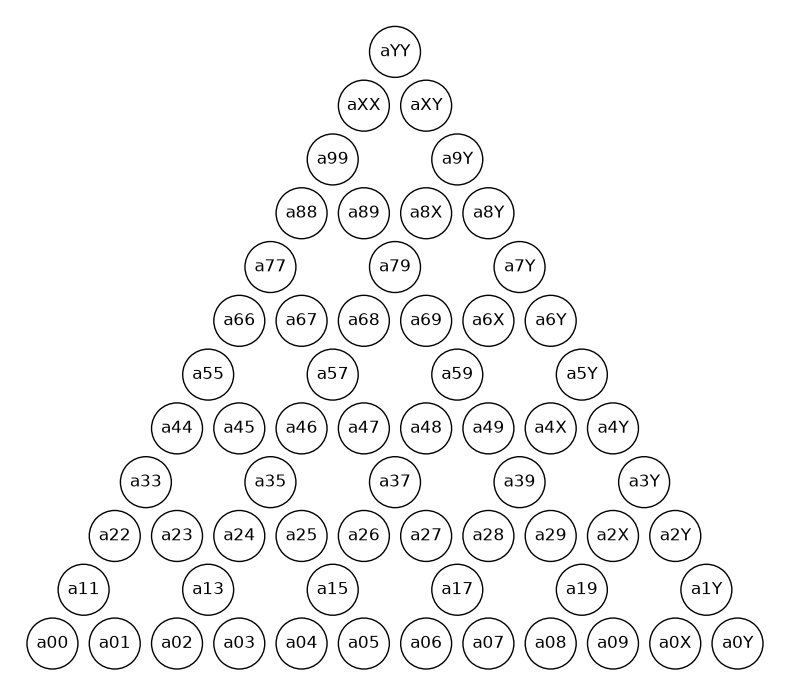

In [5]:
# C enum / 출력 순서에 정확히 대응하는 63개 값
rows_labels = [
    ["aYY"],
    ["aXX", "aXY"],
    ["a99", -1, "a9Y"],
    ["a88", "a89", "a8X", "a8Y"],
    ["a77", -1, "a79", -1, "a7Y"],
    ["a66", "a67", "a68", "a69", "a6X", "a6Y"],
    ["a55", -1, "a57", -1, "a59", -1, "a5Y"],
    ["a44", "a45", "a46", "a47", "a48", "a49", "a4X", "a4Y"],
    ["a33", -1, "a35", -1, "a37", -1, "a39", -1, "a3Y"],
    ["a22", "a23", "a24", "a25", "a26", "a27", "a28", "a29", "a2X", "a2Y"],
    ["a11", -1, "a13", -1, "a15", -1, "a17", -1, "a19", -1, "a1Y"],
    ["a00", "a01", "a02", "a03", "a04", "a05", "a06", "a07", "a08", "a09", "a0X", "a0Y"],
]
plot_trihexagonal(rows_labels, print_rows=False)
pass

#### Example Solution

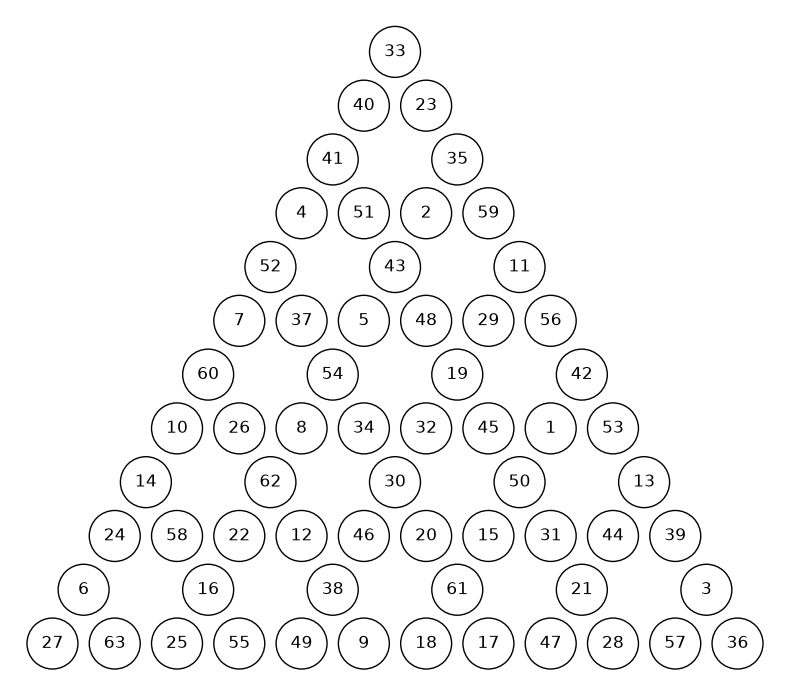

In [7]:
values = [
    33, 40, 23, 41, 35, 4, 51, 2, 59,
    52, 43, 11, 7, 37, 5, 48, 29, 56,
    60, 54, 19, 42, 10, 26, 8, 34, 32, 45, 1, 53,
    14, 62, 30, 50, 13, 24, 58, 22, 12, 46, 20, 15,
    31, 44, 39, 6, 16, 38, 61, 21,
    3, 27, 63, 25, 55, 49, 9, 18, 17, 47, 28, 57, 36
]
plot_trihexagonal(values, print_rows=False)
pass

#### Example Solution with Vertex Labels

In [9]:
import matplotlib.pyplot as plt

def plot_trihexagonal_double(values, labels, print_rows=False):
    def to_rows(data):
        if isinstance(data[0], (list, tuple)):
            return data
        else:
            it = iter(data)
            return [
                [-1 if item == -1 else next(it) for item in row]
                for row in rows_labels
            ]

    rows = to_rows(values)
    rows_names = to_rows(labels)

    radius = 0.9
    x_spacing = 2.2
    y_spacing = 1.9

    fig, ax = plt.subplots(figsize=(9, 9))
    ax.set_aspect("equal")
    ax.axis("off")

    max_len = max(len(r) for r in rows)
    xs, ys = [], []

    for ridx, row in enumerate(rows):
        offset = (max_len - len(row)) * x_spacing / 2
        for cidx, val in enumerate(row):
            if val == -1:
                continue

            x = offset + cidx * x_spacing
            y = -ridx * y_spacing
            xs.append(x)
            ys.append(y)

            circle = plt.Circle((x, y), radius, fill=False, linewidth=1.2)
            ax.add_patch(circle)

            ax.plot(
                [x - radius * 0.85, x + radius * 0.85],
                [y, y],
                linewidth=1.0, color="black"
            )

            ax.text(
                x, y + radius * 0.35, str(val),
                ha="center", va="center", fontsize=11
            )

            ax.text(
                x, y - radius * 0.35, str(rows_names[ridx][cidx]),
                ha="center", va="center", fontsize=11
            )

    margin = 1.5
    ax.set_xlim(min(xs) - margin, max(xs) + margin)
    ax.set_ylim(min(ys) - margin, max(ys) + margin)

    plt.tight_layout()
    plt.show()

    if print_rows:
        print("rows =")
        for row in rows:
            print(row)

    return rows

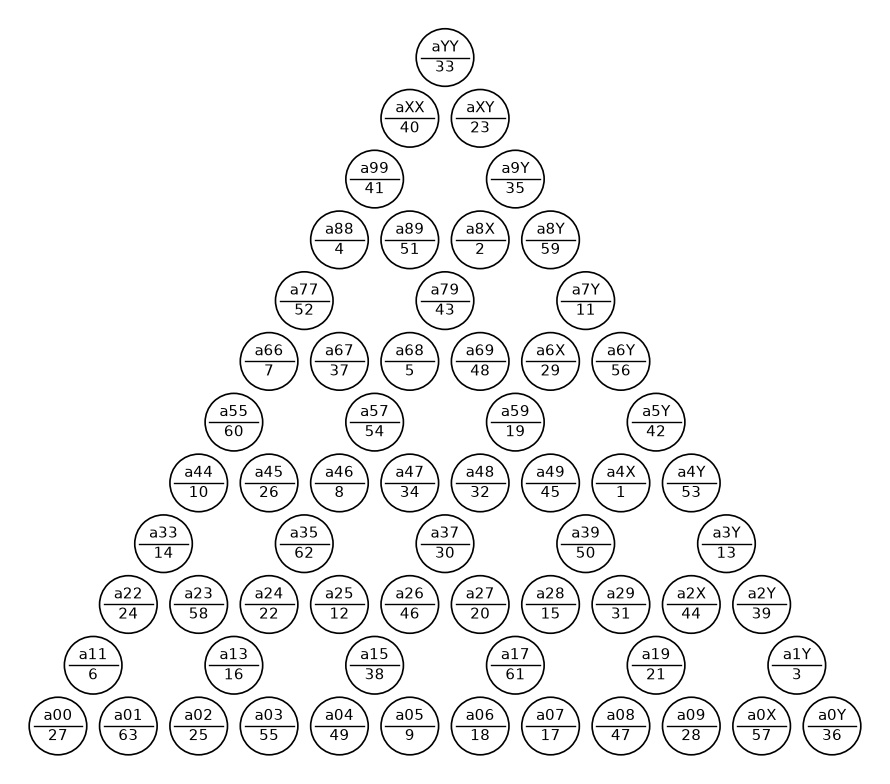

In [10]:
plot_trihexagonal_double(rows_labels, values, print_rows=False)
pass

In [11]:
pycode='''
i=0
for a47 in range(33,64):
    for a48 in range(int((96-a47)/2)+1, min(a47,96-a47)):
        a37 = 96 - a48 - a47
        for a46 in set(range(1,64))-{a37,a47,a48}:
            a57=96-a46-a47
            if a57 in set(range(1,64))-{a37,a47,a48,a46}:
                for a49 in set(range(1,64))-{a37,a47,a48,a46,a57}:
                    a59=96-a49-a48
                    a79=96-a46-a49
                    if {a49,a59,a79}.issubset(set(range(1,64))-{a37,a47,a48,a46,a57}):
                        if len({a49,a59,a79})==3:
                            for a68 in set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57}:
                                a69=96-a68-a79
                                a67=96-a57-a68
                                a6X=96-a59-a69
                                if {a68,a69,a67,a6X}.issubset(set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57}):
                                    if len({a68,a69,a67,a6X})==4:
                                        for a26 in set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57,a68,a69,a67,a6X}:
                                            a27=96-a26-a37
                                            a24=96-a57-a27
                                            a29=96-a59-a26
                                            if {a26,a27,a24,a29}.issubset(set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57,a68,a69,a67,a6X}):
                                                if len({a26,a27,a24,a29})==4:
                                                    for a25 in set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57,a68,a69,a67,a6X,a26,a27,a24,a29}:
                                                        a35=96-a24-a25
                                                        a45=96-a35-a46
                                                        a15=96-a25-a26
                                                        if {a25,a35,a45,a15}.issubset(set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57,a68,a69,a67,a6X,a26,a27,a24,a29}):
                                                            if len({a25,a35,a45,a15})==4:
                                                                for a28 in set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57,a68,a69,a67,a6X,a26,a27,a24,a29,a25,a35,a45,a15}:
                                                                    a39=96-a28-a29
                                                                    a4X=96-a39-a49
                                                                    a17=96-a27-a28
                                                                    if {a28,a39,a4X,a17}.issubset(set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57,a68,a69,a67,a6X,a26,a27,a24,a29,a25,a35,a45,a15}):
                                                                        if len({a28,a39,a4X,a17})==4:
                                                                            set39=set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57,a68,a69,a67,a6X,a26,a27,a24,a29,a25,a35,a45,a15,a28,a39,a4X,a17}
                                                                            for a89 in set39:
                                                                                a8X=96-a89-a79
                                                                                if a8X in set39:
                                                                                    if a8X!=a89:
                                                                                        for a77 in set39-{a89,a8X}:
                                                                                            a66=96-a77-a67
                                                                                            a44=96-a47-a77
                                                                                            a55=96-a44-a45
                                                                                            a22=96-a25-a55
                                                                                            a99=96-a22-a29
                                                                                            a88=96-a99-a89
                                                                                            if {a22,a44,a55,a66,a77,a88,a99}.issubset(set39-{a89,a8X}):
                                                                                                if len({a22,a44,a55,a66,a77,a88,a99})==7:
                                                                                                    for a7Y in set39-{a89,a8X,a22,a44,a55,a66,a77,a88,a99}:
                                                                                                        a6Y=96-a7Y-a6X
                                                                                                        aYY=96-a6Y-a66
                                                                                                        a4Y=96-a48-a7Y
                                                                                                        a5Y=96-a4Y-a4X
                                                                                                        a2Y=96-a28-a5Y
                                                                                                        a9Y=96-a24-a2Y
                                                                                                        a8Y=96-a9Y-a8X
                                                                                                        if {a2Y,a4Y,a5Y,a6Y,a7Y,a8Y,a9Y,aYY}.issubset(set39-{a89,a8X,a22,a44,a55,a66,a77,a88,a99}):
                                                                                                            if len({a2Y,a4Y,a5Y,a6Y,a7Y,a8Y,a9Y,aYY})==8:
                                                                                                                for a23 in set39-{a89,a8X,a22,a44,a55,a66,a77,a88,a99,a2Y,a4Y,a5Y,a6Y,a7Y,a8Y,a9Y,aYY}:
                                                                                                                    a33=96-a22-a23
                                                                                                                    a13=96-a23-a24
                                                                                                                    if {a13,a23,a33}.issubset(set39-{a89,a8X,a22,a44,a55,a66,a77,a88,a99,a2Y,a4Y,a5Y,a6Y,a7Y,a8Y,a9Y,aYY}):
                                                                                                                        if len({a13,a23,a33})==3:
                                                                                                                            for a00 in set39-{a89,a8X,a22,a44,a55,a66,a77,a88,a99,a2Y,a4Y,a5Y,a6Y,a7Y,a8Y,a9Y,aYY,a13,a23,a33}:
                                                                                                                                a03=96-a00-a33
                                                                                                                                a05=96-a00-a55
                                                                                                                                a07=96-a00-a77
                                                                                                                                a09=96-a00-a99
                                                                                                                                a0Y=96-a00-aYY
                                                                                                                                a02=96-a13-a03
                                                                                                                                a04=96-a15-a05
                                                                                                                                a06=96-a17-a07
                                                                                                                                if {a00,a02,a03,a04,a05,a06,a07,a09,a0Y}.issubset(set39-{a89,a8X,a22,a44,a55,a66,a77,a88,a99,a2Y,a4Y,a5Y,a6Y,a7Y,a8Y,a9Y,aYY,a13,a23,a33}):
                                                                                                                                    if len({a00,a02,a03,a04,a05,a06,a07,a09,a0Y})==9:
                                                                                                                                        set10=set39-{a89,a8X,a22,a44,a55,a66,a77,a88,a99,a2Y,a4Y,a5Y,a6Y,a7Y,a8Y,a9Y,aYY,a13,a23,a33}-{a00,a02,a03,a04,a05,a06,a07,a09,a0Y}
                                                                                                                                        for a19 in set10:
                                                                                                                                            a08=96-a19-a09
                                                                                                                                            a2X=96-a19-a29
                                                                                                                                            a3Y=96-a2X-a2Y
                                                                                                                                            if {a19,a08,a2X,a3Y}.issubset(set10):
                                                                                                                                                if len({a19,a08,a2X,a3Y})==4:
                                                                                                                                                    set6=set10-{a19,a08,a2X,a3Y}
                                                                                                                                                    for aXX in set6:
                                                                                                                                                        aXY=96-aXX-aYY
                                                                                                                                                        if aXY in set6-{aXX} and aXX>aXY:
                                                                                                                                                            for a0X in set6-{aXX,aXY}:
                                                                                                                                                                a1Y= 96-a0X-a0Y
                                                                                                                                                                if a1Y in set6-{aXX,aXY,a0X} and a0X>a1Y:
                                                                                                                                                                    for a01 in set6-{aXX,aXY,a0X,a1Y}:
                                                                                                                                                                        a11=96-a01-a00
                                                                                                                                                                        if a11 in set6-{aXX,aXY,a0X,a1Y,a01} and a01>a11:
                                                                                                                                                                            i+=1      
                                                                                                                                                                            print(i,"th: solution:", aYY,aXX,aXY,a99,a9Y,a88,a89,a8X,a8Y,a77,a79,a7Y,a66,a67,a68,a69,a6X,a6Y,a55,a57,a59,a5Y,a44,a45,a46,a47,a48,a49,a4X,a4Y,a33,a35,a37,a39,a3Y,a22,a23,a24,a25,a26,a27,a28,a29,a2X,a2Y,a11,a13,a15,a17,a19,a1Y,a00,a01,a02,a03,a04,a05,a06,a07,a08,a09,a0X,a0Y)
                                                                                                                                
                                                                                                                
                                                                                                                                                                                                                                                                                                                                                             
print(i)
'''
print(pycode)


i=0
for a47 in range(33,64):
    for a48 in range(int((96-a47)/2)+1, min(a47,96-a47)):
        a37 = 96 - a48 - a47
        for a46 in set(range(1,64))-{a37,a47,a48}:
            a57=96-a46-a47
            if a57 in set(range(1,64))-{a37,a47,a48,a46}:
                for a49 in set(range(1,64))-{a37,a47,a48,a46,a57}:
                    a59=96-a49-a48
                    a79=96-a46-a49
                    if {a49,a59,a79}.issubset(set(range(1,64))-{a37,a47,a48,a46,a57}):
                        if len({a49,a59,a79})==3:
                            for a68 in set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57}:
                                a69=96-a68-a79
                                a67=96-a57-a68
                                a6X=96-a59-a69
                                if {a68,a69,a67,a6X}.issubset(set(range(1,64))-{a49,a59,a79,a37,a47,a48,a46,a57}):
                                    if len({a68,a69,a67,a6X})==4:
                                        for a26 in set(range

In [12]:
ccode='''
#include <inttypes.h>
#include <stdbool.h>
#include <stdint.h>
#include <stdio.h>
#include <stdarg.h>

/*
    Runtime MODE selection:

    MODE 1 : Full search starting from a47=33; stop at the first solution.
    MODE 2 : Search only the specified (a47, a48) pair; output all solutions for that pair.
    MODE 3 : Full search starting from a47=33; output all solutions.
    MODE 4 : Enter a47 at runtime.
             -> Automatically search all valid a48 values for the given a47.
    MODE 5 : Enter a47, a48 start, and a48 end at runtime.
             -> Search the specified range.
    MODE 6 : Enter a47 and a chunk number at runtime.
             -> Divide all valid a48 values into balanced chunks,
                each containing at most CHUNK_SIZE cases.
             -> Search only the selected chunk.

    Output files are automatically generated for each execution and opened in "w" mode.
    Different ranges or chunks use distinct filenames, so they do not overwrite
    each other's results, regardless of execution order.
*/

#define FIXED_A47 35
#define FIXED_A48 31
#define CHUNK_SIZE 9

/* Output order matches the output order of the original Python code. */
enum {
    aYY, aXX, aXY, a99, a9Y, a88, a89, a8X, a8Y,
    a77, a79, a7Y, a66, a67, a68, a69, a6X, a6Y,
    a55, a57, a59, a5Y, a44, a45, a46, a47, a48, a49, a4X, a4Y,
    a33, a35, a37, a39, a3Y, a22, a23, a24, a25, a26, a27, a28,
    a29, a2X, a2Y, a11, a13, a15, a17, a19, a1Y,
    a00, a01, a02, a03, a04, a05, a06, a07, a08, a09, a0X, a0Y,
    COUNT
};

_Static_assert(COUNT == 63, "Expected exactly 63 nodes");

static int v[COUNT];
static uint64_t solutions = 0;
static const uint64_t FULL = (UINT64_C(1) << 63) - 1;

static int mode = 0;
static FILE *out = NULL;


/* Output to both the console and the result file. */
static void log_printf(const char *fmt, ...)
{
    va_list ap;

    va_start(ap, fmt);
    vprintf(fmt, ap);
    va_end(ap);

    if (out != NULL) {
        va_start(ap, fmt);
        vfprintf(out, fmt, ap);
        va_end(ap);
        fflush(out);
    }
}


static bool open_output(const char *filename)
{
    out = fopen(filename, "w");

    if (out == NULL) {
        perror(filename);
        return false;
    }

    printf("output file: %s\n", filename);
    return true;
}


/*
    Minimum and maximum valid values of a48 for a47 = x.

    Conditions:
        a47 > a48 > a37
        a47 + a48 + a37 = 96

    Equivalently:
        x > y > 96 - x - y
*/
static int a48_min(int x)
{
    return (96 - x) / 2 + 1;
}


static int a48_max(int x)
{
    int m = x - 1;

    if (m > 95 - x)
        m = 95 - x;

    return m;
}


static bool valid_a47(int x)
{
    return x >= 33 && x <= 63 &&
           a48_min(x) <= a48_max(x);
}


static bool put(uint64_t *used, int id, int value)
{
    if (value < 1 || value > 63)
        return false;

    uint64_t bit = UINT64_C(1) << (value - 1);

    if (*used & bit)
        return false;

    *used |= bit;
    v[id] = value;

    return true;
}


/* At each stage, select one free variable and determine the remaining values so that their sum is 96. */
#define P(id, expression) \
    do { \
        if (!put(used, (id), (expression))) return false; \
    } while (0)


static bool assign_stage(int stage, int x, uint64_t *used)
{
    switch (stage) {

    case 1:
        P(a46, x);
        P(a57, 96 - v[a46] - v[a47]);
        break;

    case 2:
        P(a49, x);
        P(a59, 96 - v[a49] - v[a48]);
        P(a79, 96 - v[a46] - v[a49]);
        break;

    case 3:
        P(a68, x);
        P(a69, 96 - v[a68] - v[a79]);
        P(a67, 96 - v[a57] - v[a68]);
        P(a6X, 96 - v[a59] - v[a69]);
        break;

    case 4:
        P(a26, x);
        P(a27, 96 - v[a26] - v[a37]);
        P(a24, 96 - v[a57] - v[a27]);
        P(a29, 96 - v[a59] - v[a26]);
        break;

    case 5:
        P(a25, x);
        P(a35, 96 - v[a24] - v[a25]);
        P(a45, 96 - v[a35] - v[a46]);
        P(a15, 96 - v[a25] - v[a26]);
        break;

    case 6:
        P(a28, x);
        P(a39, 96 - v[a28] - v[a29]);
        P(a4X, 96 - v[a39] - v[a49]);
        P(a17, 96 - v[a27] - v[a28]);
        break;

    case 7:
        P(a89, x);
        P(a8X, 96 - v[a89] - v[a79]);
        break;

    case 8:
        P(a77, x);
        P(a66, 96 - v[a77] - v[a67]);
        P(a44, 96 - v[a47] - v[a77]);
        P(a55, 96 - v[a44] - v[a45]);
        P(a22, 96 - v[a25] - v[a55]);
        P(a99, 96 - v[a22] - v[a29]);
        P(a88, 96 - v[a99] - v[a89]);
        break;

    case 9:
        P(a7Y, x);
        P(a6Y, 96 - v[a7Y] - v[a6X]);
        P(aYY, 96 - v[a6Y] - v[a66]);
        P(a4Y, 96 - v[a48] - v[a7Y]);
        P(a5Y, 96 - v[a4Y] - v[a4X]);
        P(a2Y, 96 - v[a28] - v[a5Y]);
        P(a9Y, 96 - v[a24] - v[a2Y]);
        P(a8Y, 96 - v[a9Y] - v[a8X]);
        break;

    case 10:
        P(a23, x);
        P(a33, 96 - v[a22] - v[a23]);
        P(a13, 96 - v[a23] - v[a24]);
        break;

    case 11:
        P(a00, x);
        P(a03, 96 - v[a00] - v[a33]);
        P(a05, 96 - v[a00] - v[a55]);
        P(a07, 96 - v[a00] - v[a77]);
        P(a09, 96 - v[a00] - v[a99]);
        P(a0Y, 96 - v[a00] - v[aYY]);
        P(a02, 96 - v[a13] - v[a03]);
        P(a04, 96 - v[a15] - v[a05]);
        P(a06, 96 - v[a17] - v[a07]);
        break;

    case 12:
        P(a19, x);
        P(a08, 96 - v[a19] - v[a09]);
        P(a2X, 96 - v[a19] - v[a29]);
        P(a3Y, 96 - v[a2X] - v[a2Y]);
        break;

    case 13:
        P(aXX, x);
        P(aXY, 96 - v[aXX] - v[aYY]);

        if (v[aXX] <= v[aXY])
            return false;
        break;

    case 14:
        P(a0X, x);
        P(a1Y, 96 - v[a0X] - v[a0Y]);

        if (v[a0X] <= v[a1Y])
            return false;
        break;

    case 15:
        P(a01, x);
        P(a11, 96 - v[a01] - v[a00]);

        if (v[a01] <= v[a11])
            return false;
        break;

    default:
        return false;
    }

    return true;
}

#undef P


static bool search(int stage, uint64_t used)
{
    if (stage == 16) {

        if (used != FULL)
            return false;

        ++solutions;

        log_printf("%" PRIu64 "th: solution:", solutions);

        for (int j = 0; j < COUNT; ++j)
            log_printf(" %d", v[j]);

        log_printf("\n");

        /* Only MODE 1 terminates the entire search immediately upon finding the first solution. */
        return mode == 1;
    }

    for (int x = 1; x <= 63; ++x) {

        if (used & (UINT64_C(1) << (x - 1)))
            continue;

        uint64_t next_used = used;

        if (assign_stage(stage, x, &next_used) &&
            search(stage + 1, next_used))
            return true;
    }

    return false;
}


/*
    Search for solutions for the given (a47, a48) pair.
    a37 = 96 - a47 - a48
*/
static bool search_pair(int x, int y)
{
    uint64_t used = 0;

    if (!put(&used, a47, x))
        return false;

    if (!put(&used, a48, y))
        return false;

    if (!put(&used, a37, 96 - x - y))
        return false;

    log_printf(
        "a47 = %d, a48 = %d, a37 = %d\n",
        x, y, 96 - x - y
    );

    fflush(stdout);

    return search(1, used);
}


/* Search a48 from start to end for a given a47. */
static void search_range(int x, int start, int end)
{
    for (int y = start; y <= end; ++y)
        search_pair(x, y);
}


int main(void)
{
    char filename[256];

    printf(
        "Select mode:\n"
        "  1 = full search, stop at first solution\n"
        "  2 = one fixed (a47, a48) pair\n"
        "  3 = full search, all solutions\n"
        "  4 = one a47, all valid a48\n"
        "  5 = one a47, selected a48 range\n"
        "  6 = one a47, selected balanced chunk\n"
        "mode: "
    );
    fflush(stdout);

    if (scanf("%d", &mode) != 1 || mode < 1 || mode > 6) {
        fprintf(stderr, "Invalid mode.\n");
        return 1;
    }


    if (mode == 1) {

        snprintf(filename, sizeof(filename),
                 "trihex63_mode1_first_solution.txt");

        if (!open_output(filename))
            return 1;

        log_printf("mode 1: full search, first solution only\n");

        for (int x = 33; x <= 63; ++x) {

            int start = a48_min(x);
            int end   = a48_max(x);

            for (int y = start; y <= end; ++y) {

                if (search_pair(x, y))
                    goto done;
            }
        }
    }


    else if (mode == 2) {

        int x, y;

        printf("a47 [%d]: ", FIXED_A47);
        fflush(stdout);
        if (scanf("%d", &x) != 1) {
            fprintf(stderr, "Input error.\n");
            return 1;
        }

        printf("a48 [%d]: ", FIXED_A48);
        fflush(stdout);
        if (scanf("%d", &y) != 1) {
            fprintf(stderr, "Input error.\n");
            return 1;
        }

        if (!valid_a47(x) ||
            y < a48_min(x) ||
            y > a48_max(x)) {

            fprintf(
                stderr,
                "Invalid pair. Valid a48 range for a47=%d is %d..%d\n",
                x, a48_min(x), a48_max(x)
            );
            return 1;
        }

        snprintf(filename, sizeof(filename),
                 "trihex63_a47_%02d_a48_%02d.txt",
                 x, y);

        if (!open_output(filename))
            return 1;

        log_printf(
            "mode 2: a47=%d, a48=%d\n",
            x, y
        );

        search_pair(x, y);
    }


    else if (mode == 3) {

        snprintf(filename, sizeof(filename),
                 "trihex63_all_solutions.txt");

        if (!open_output(filename))
            return 1;

        log_printf("mode 3: full search, all solutions\n");

        for (int x = 33; x <= 63; ++x) {

            int start = a48_min(x);
            int end   = a48_max(x);

            search_range(x, start, end);
        }
    }


    else if (mode == 4) {

        int x;

        printf("a47: ");
        fflush(stdout);

        if (scanf("%d", &x) != 1) {
            fprintf(stderr, "Input error.\n");
            return 1;
        }

        if (!valid_a47(x)) {
            fprintf(stderr, "Invalid a47: %d\n", x);
            return 1;
        }

        int start = a48_min(x);
        int end   = a48_max(x);

        snprintf(filename, sizeof(filename),
                 "trihex63_a47_%02d_all_a48_%02d_%02d.txt",
                 x, start, end);

        if (!open_output(filename))
            return 1;

        log_printf(
            "mode 4: a47=%d, a48=%d..%d (%d cases)\n",
            x, start, end, end - start + 1
        );

        search_range(x, start, end);
    }


    else if (mode == 5) {

        int x;
        int start;
        int end;

        printf("a47: ");
        fflush(stdout);

        if (scanf("%d", &x) != 1) {
            fprintf(stderr, "Input error.\n");
            return 1;
        }

        if (!valid_a47(x)) {
            fprintf(stderr, "Invalid a47: %d\n", x);
            return 1;
        }

        int valid_start = a48_min(x);
        int valid_end   = a48_max(x);

        printf(
            "valid a48 range: %d .. %d\n",
            valid_start, valid_end
        );

        printf("a48 start: ");
        fflush(stdout);

        if (scanf("%d", &start) != 1) {
            fprintf(stderr, "Input error.\n");
            return 1;
        }

        printf("a48 end: ");
        fflush(stdout);

        if (scanf("%d", &end) != 1) {
            fprintf(stderr, "Input error.\n");
            return 1;
        }

        if (start < valid_start ||
            end > valid_end ||
            start > end) {

            fprintf(
                stderr,
                "Invalid range. Valid a48 range for a47=%d is %d..%d\n",
                x, valid_start, valid_end
            );

            return 1;
        }

        snprintf(filename, sizeof(filename),
                 "trihex63_a47_%02d_a48_%02d_%02d.txt",
                 x, start, end);

        if (!open_output(filename))
            return 1;

        log_printf(
            "mode 5: a47=%d, a48=%d..%d (%d cases)\n",
            x, start, end, end - start + 1
        );

        search_range(x, start, end);
    }


    else if (mode == 6) {

        int x;
        int chunk;

        printf("a47: ");
        fflush(stdout);

        if (scanf("%d", &x) != 1) {
            fprintf(stderr, "Input error.\n");
            return 1;
        }

        if (!valid_a47(x)) {
            fprintf(stderr, "Invalid a47: %d\n", x);
            return 1;
        }

        int valid_start = a48_min(x);
        int valid_end   = a48_max(x);
        int cases       = valid_end - valid_start + 1;

        int chunks =
            (cases + CHUNK_SIZE - 1) / CHUNK_SIZE;

        int base  = cases / chunks;
        int extra = cases % chunks;

        printf(
            "a48 range: %d .. %d (%d cases)\n",
            valid_start, valid_end, cases
        );

        printf(
            "chunks: %d (balanced, max %d cases each)\n",
            chunks, CHUNK_SIZE
        );

        int pos = valid_start;

        for (int c = 1; c <= chunks; ++c) {

            int size =
                base + (c <= extra ? 1 : 0);

            int s = pos;
            int e = s + size - 1;

            printf(
                "  chunk %d: a48=%d..%d (%d cases)\n",
                c, s, e, size
            );

            pos = e + 1;
        }

        printf("chunk: ");
        fflush(stdout);

        if (scanf("%d", &chunk) != 1) {
            fprintf(stderr, "Input error.\n");
            return 1;
        }

        if (chunk < 1 || chunk > chunks) {

            fprintf(
                stderr,
                "Invalid chunk. Valid chunk range is 1..%d\n",
                chunks
            );

            return 1;
        }

        int before =
            (chunk - 1) * base;

        if (chunk - 1 < extra)
            before += chunk - 1;
        else
            before += extra;

        int size =
            base + (chunk <= extra ? 1 : 0);

        int start =
            valid_start + before;

        int end =
            start + size - 1;

        snprintf(filename, sizeof(filename),
                 "trihex63_a47_%02d_chunk_%02d_of_%02d_a48_%02d_%02d.txt",
                 x, chunk, chunks, start, end);

        if (!open_output(filename))
            return 1;

        log_printf(
            "mode 6: a47=%d, chunk=%d/%d, "
            "a48=%d..%d (%d cases)\n",
            x, chunk, chunks, start, end, size
        );

        search_range(x, start, end);
    }


done:
    log_printf("total: %" PRIu64 "\n", solutions);

    if (out != NULL)
        fclose(out);

    return 0;
}'''
print(ccode)


#include <inttypes.h>
#include <stdbool.h>
#include <stdint.h>
#include <stdio.h>
#include <stdarg.h>

/*
    Runtime MODE selection:

    MODE 1 : Full search starting from a47=33; stop at the first solution.
    MODE 2 : Search only the specified (a47, a48) pair; output all solutions for that pair.
    MODE 3 : Full search starting from a47=33; output all solutions.
    MODE 4 : Enter a47 at runtime.
             -> Automatically search all valid a48 values for the given a47.
    MODE 5 : Enter a47, a48 start, and a48 end at runtime.
             -> Search the specified range.
    MODE 6 : Enter a47 and a chunk number at runtime.
             -> Divide all valid a48 values into balanced chunks,
                each containing at most CHUNK_SIZE cases.
             -> Search only the selected chunk.

    Output files are automatically generated for each execution and opened in "w" mode.
    Different ranges or chunks use distinct filenames, so they do not overwrite
    each other's r

#### Find one solution

In [14]:
myresult='''gcc -O3 -std=c11 -Wall -Wextra trihex63_runtime_mode_output_en.c -o trihex63_runtime_mode_output_en

trihex63_runtime_mode_output_en.exe

Select mode:
  1 = full search, stop at first solution
  2 = one fixed (a47, a48) pair
  3 = full search, all solutions
  4 = one a47, all valid a48
  5 = one a47, selected a48 range
  6 = one a47, selected balanced chunk
mode 1: full search, first solution only
a47 = 33, a48 = 32, a37 = 31
a47 = 34, a48 = 32, a37 = 30
1th: solution: 33 40 23 41 35 4 51 2 59 52 43 11 7 37 5 48 29 56 60 54 19 42 10 26 8 34 32 45 1 53 14 62 30 50 13 24 58 22 12 46 20 15 31 44 39 6 16 38 61 21 3 27 63 25 55 49 9 18 17 47 28 57 36
total: 1'''
print(myresult)

gcc -O3 -std=c11 -Wall -Wextra trihex63_runtime_mode_output_en.c -o trihex63_runtime_mode_output_en

trihex63_runtime_mode_output_en.exe

Select mode:
  1 = full search, stop at first solution
  2 = one fixed (a47, a48) pair
  3 = full search, all solutions
  4 = one a47, all valid a48
  5 = one a47, selected a48 range
  6 = one a47, selected balanced chunk
mode 1: full search, first solution only
a47 = 33, a48 = 32, a37 = 31
a47 = 34, a48 = 32, a37 = 30
1th: solution: 33 40 23 41 35 4 51 2 59 52 43 11 7 37 5 48 29 56 60 54 19 42 10 26 8 34 32 45 1 53 14 62 30 50 13 24 58 22 12 46 20 15 31 44 39 6 16 38 61 21 3 27 63 25 55 49 9 18 17 47 28 57 36
total: 1


#### Example: Finding Magic Solutions for $a_{47} = 34$

In [16]:
myresult='''gcc -O3 -std=c11 -Wall -Wextra trihex63_runtime_mode_output_en.c -o trihex63_runtime_mode_output_en

trihex63_runtime_mode_output_en.exe

Select mode:
  1 = full search, stop at first solution
  2 = one fixed (a47, a48) pair
  3 = full search, all solutions
  4 = one a47, all valid a48
  5 = one a47, selected a48 range
  6 = one a47, selected balanced chunk
mode: 4
a47: 34
output file: trihex63_a47_34_all_a48_32_33.txt

mode 4: a47=34, a48=32..33 (2 cases)
a47 = 34, a48 = 32, a37 = 30
1th: solution: 33 40 23 41 35 4 51 2 59 52 43 11 7 37 5 48 29 56 60 54 19 42 10 26 8 34 32 45 1 53 14 62 30 50 13 24 58 22 12 46 20 15 31 44 39 6 16 38 61 21 3 27 63 25 55 49 9 18 17 47 28 57 36
2th: solution: 35 56 5 31 22 6 59 19 55 58 18 7 15 23 28 50 43 46 29 45 3 37 4 63 17 34 32 61 2 57 62 16 30 33 40 13 21 26 54 41 25 11 52 8 48 38 49 1 60 36 10 14 44 27 20 42 53 12 24 9 51 39 47
3th: solution: 35 56 5 31 22 6 59 19 55 58 18 7 15 23 28 50 43 46 29 45 3 37 4 63 17 34 32 61 2 57 62 16 30 33 40 14 20 27 53 42 24 12 51 9 47 39 49 1 60 36 10 13 44 26 21 41 54 11 25 8 52 38 48
4th: solution: 28 61 7 36 25 17 43 20 51 47 33 11 46 3 49 14 63 22 55 44 19 8 15 26 18 34 32 45 35 53 9 52 30 16 5 39 48 42 2 56 10 59 21 62 29 1 6 38 27 13 24 37 58 40 50 54 4 57 12 60 23 41 31
5th: solution: 16 54 26 12 17 56 28 55 24 39 13 7 53 4 52 31 62 27 10 40 3 18 23 63 22 34 32 61 21 57 43 11 30 14 9 38 15 37 48 47 19 36 46 45 42 20 44 1 41 5 8 51 25 50 2 60 35 49 6 58 33 59 29
6th: solution: 17 54 25 13 16 55 28 56 24 40 12 7 52 4 53 31 62 27 11 39 3 18 22 63 23 34 32 61 21 57 44 10 30 14 9 37 15 38 48 47 19 36 46 45 42 20 43 1 41 5 8 50 26 51 2 60 35 49 6 58 33 59 29
a47 = 34, a48 = 33, a37 = 29
7th: solution: 53 40 3 51 60 23 22 16 20 54 58 28 24 18 17 21 49 19 52 61 26 46 8 36 1 34 33 37 15 35 2 59 29 44 43 38 56 31 6 63 4 45 7 48 5 14 9 27 47 41 30 32 50 25 62 57 12 39 10 42 13 55 11
8th: solution: 45 49 2 42 43 46 8 48 5 61 40 13 15 20 17 39 47 36 54 59 10 9 1 41 3 34 33 53 37 50 14 52 29 6 7 19 63 21 23 51 16 55 35 57 32 28 12 22 25 4 31 24 44 26 58 56 18 60 11 62 30 38 27
9th: solution: 47 40 9 46 54 8 42 1 41 48 53 28 44 4 37 6 63 5 43 55 27 59 14 39 7 34 33 36 2 35 45 50 29 58 23 38 13 31 15 57 10 26 12 62 11 3 52 24 60 22 30 32 61 25 19 51 21 20 16 56 18 49 17
10th: solution: 38 55 3 32 41 5 59 2 53 19 35 48 54 23 51 10 44 4 6 22 42 20 43 47 40 34 33 21 61 15 57 9 29 14 58 28 11 25 62 18 49 46 36 8 30 13 60 16 1 52 26 27 56 24 12 17 63 45 50 7 37 39 31
total: 10'''
print(myresult)

gcc -O3 -std=c11 -Wall -Wextra trihex63_runtime_mode_output_en.c -o trihex63_runtime_mode_output_en

trihex63_runtime_mode_output_en.exe

Select mode:
  1 = full search, stop at first solution
  2 = one fixed (a47, a48) pair
  3 = full search, all solutions
  4 = one a47, all valid a48
  5 = one a47, selected a48 range
  6 = one a47, selected balanced chunk
mode: 4
a47: 34
output file: trihex63_a47_34_all_a48_32_33.txt

mode 4: a47=34, a48=32..33 (2 cases)
a47 = 34, a48 = 32, a37 = 30
1th: solution: 33 40 23 41 35 4 51 2 59 52 43 11 7 37 5 48 29 56 60 54 19 42 10 26 8 34 32 45 1 53 14 62 30 50 13 24 58 22 12 46 20 15 31 44 39 6 16 38 61 21 3 27 63 25 55 49 9 18 17 47 28 57 36
2th: solution: 35 56 5 31 22 6 59 19 55 58 18 7 15 23 28 50 43 46 29 45 3 37 4 63 17 34 32 61 2 57 62 16 30 33 40 13 21 26 54 41 25 11 52 8 48 38 49 1 60 36 10 14 44 27 20 42 53 12 24 9 51 39 47
3th: solution: 35 56 5 31 22 6 59 19 55 58 18 7 15 23 28 50 43 46 29 45 3 37 4 63 17 34 32 61 2 57 62 16 30 33 40 14 20 

In [17]:
%run count_trihex63.py order6results --triple 63 32 1 --strict

Files: 31/31, triples: 481/481
Solutions in read files: 3,222; multiplied by 8: 25,776
Complement pairs: 256; match=256, mismatch=0, unknown=0
Missing files: 0; log errors: 0
Query (63, 32, 1): 26 solutions
Complement (63, 32, 1): 26 solutions
Saved CSV/JSON in: B:\Jupyter\Cprogram\trihexfinalprogram\order6analysis


In [18]:
import pandas as pd
import json
from pathlib import Path
from IPython.display import display, Markdown

folder = Path("trihex63_count_results")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Overall summary
with open(folder / "summary.json", "r", encoding="utf-8") as f:
    summary = json.load(f)

display(Markdown("#### Overall Solution Counts and Validation"))
display(pd.json_normalize(summary, sep=".").T.rename(columns={0: "Value"}))


#### Overall Solution Counts and Validation

,Value
expected_files,31
read_files,31
missing_files,[]
expected_triples,481
covered_triples,481
observed_solutions,3222
multiplied_by_8,25776
complement_pairs,256
matched_pairs,256
mismatched_pairs,[]


In [19]:
csv_files = {
    "Solution Counts by $a_{47}$": "counts_by_a47.csv",
}

dataframes = {}

for title, filename in csv_files.items():
    df = pd.read_csv(folder / filename)
    dataframes[filename] = df

    display(Markdown(f"#### {title} ({len(df):,} rows)"))
    display(df)

    base_count = df["count"].sum()
    display(Markdown(
        f"**Total Base Solutions (before accounting for corner swaps): "
        f"{base_count:,}**"
    ))

#### Solution Counts by $a_{47}$ (31 rows)

,a47,a48_min,a48_max,combinations,count,status
0,33,32,32,1,0,read
1,34,32,33,2,10,read
2,35,31,34,4,13,read
3,36,31,35,5,15,read
4,37,30,36,7,27,read
5,38,30,37,8,37,read
6,39,29,38,10,42,read
7,40,29,39,11,33,read
8,41,28,40,13,61,read
9,42,28,41,14,58,read


**Total Base Solutions (before accounting for corner swaps): 3,222**

In [20]:
total = base_count * 8 #3222

print(
    f"Total number of this magic figure is {total}, "
    f"because each of the {base_count} base solutions yields 8 different arrangements "
    f"by optionally swapping (a0X, a1Y), (a11, a01), and (aXX, aXY)."
)

Total number of this magic figure is 25776, because each of the 3222 base solutions yields 8 different arrangements by optionally swapping (a0X, a1Y), (a11, a01), and (aXX, aXY).


In [21]:
#                                             aYY
#                                         aXX     aXY
#                                     a99             a9Y
#                                 a88     a89     a8X     a8Y
#                             a77             a79             a7Y
#                         a66     a67     a68     a69     a6X     a6Y
#                     a55             a57             a59             a5Y
#                 a44     a45     a46     a47     a48     a49     a4X     a4Y
#             a33             a35             a37             a39             a3Y
#         a22     a23     a24     a25     a26     a27     a28     a29     a2X     a2Y
#     a11             a13             a15             a17             a19             a1Y
# a00     a01     a02     a03     a04     a05     a06     a07     a08     a09     a0X     a0Y

In [22]:
# Detailed enumeration results
csv_files = {
    "Solution Counts by $a_{47}$": "counts_by_a47.csv",
    "Solution Counts by Triple": "counts_by_triple.csv",
    "Complementary Triple Comparison": "complement_pairs.csv",
    "File-by-File Summary": "files_summary.csv",
}
analyfolder=Path("order6analysis")
files_df = pd.read_csv(analyfolder / "files_summary.csv")
folder = Path("./order6results")
for i in range(31):
    filename=files_df["filename"][i]
    filepath = folder / filename

    display(Markdown(f"#### {filename}"))

    if filepath.is_file():
        print(filepath.read_text(encoding="utf-8"))
    else:
        print(f"File not found: {filepath}")
print(
    f"Total number of this magic figure is {total}, "
    f"because each of the {base_count} base solutions yields 8 different arrangements "
    f"by optionally swapping (a0X, a1Y), (a11, a01), and (aXX, aXY)."
)

#### trihex63_a47_33_all_a48_32_32.txt

mode 4: a47=33, a48=32..32 (1 cases)
a47 = 33, a48 = 32, a37 = 31
total: 0



#### trihex63_a47_34_all_a48_32_33.txt

mode 4: a47=34, a48=32..33 (2 cases)
a47 = 34, a48 = 32, a37 = 30
1th: solution: 33 40 23 41 35 4 51 2 59 52 43 11 7 37 5 48 29 56 60 54 19 42 10 26 8 34 32 45 1 53 14 62 30 50 13 24 58 22 12 46 20 15 31 44 39 6 16 38 61 21 3 27 63 25 55 49 9 18 17 47 28 57 36
2th: solution: 35 56 5 31 22 6 59 19 55 58 18 7 15 23 28 50 43 46 29 45 3 37 4 63 17 34 32 61 2 57 62 16 30 33 40 13 21 26 54 41 25 11 52 8 48 38 49 1 60 36 10 14 44 27 20 42 53 12 24 9 51 39 47
3th: solution: 35 56 5 31 22 6 59 19 55 58 18 7 15 23 28 50 43 46 29 45 3 37 4 63 17 34 32 61 2 57 62 16 30 33 40 14 20 27 53 42 24 12 51 9 47 39 49 1 60 36 10 13 44 26 21 41 54 11 25 8 52 38 48
4th: solution: 28 61 7 36 25 17 43 20 51 47 33 11 46 3 49 14 63 22 55 44 19 8 15 26 18 34 32 45 35 53 9 52 30 16 5 39 48 42 2 56 10 59 21 62 29 1 6 38 27 13 24 37 58 40 50 54 4 57 12 60 23 41 31
5th: solution: 16 54 26 12 17 56 28 55 24 39 13 7 53 4 52 31 62 27 10 40 3 18 23 63 22 34 32 61 21 57 43 11 30 14 9 38 15 37 48 47 19 36 46 45 42 20 44 1 

#### trihex63_a47_35_all_a48_31_34.txt

...

mode 4: a47=61, a48=18..34 (17 cases)
a47 = 61, a48 = 18, a37 = 17
1th: solution: 12 57 27 48 5 22 26 29 62 10 41 19 46 40 53 2 39 38 8 3 55 6 25 63 32 61 18 23 31 59 14 1 17 42 16 28 54 35 60 21 58 34 20 24 56 9 7 15 4 52 13 37 50 44 45 30 51 43 49 33 11 36 47
2th: solution: 21 63 12 15 13 19 62 27 56 9 7 29 30 57 38 51 22 45 24 1 23 43 26 46 34 61 18 55 4 49 58 16 17 37 14 28 10 36 44 20 59 6 53 35 47 3 50 32 31 8 2 33 60 41 5 25 39 11 54 40 48 52 42
a47 = 61, a48 = 19, a37 = 16
3th: solution: 2 52 42 15 26 34 47 10 60 4 39 14 41 51 17 40 29 53 11 28 27 30 31 54 7 61 19 50 3 63 38 35 16 43 33 37 21 13 48 25 55 9 44 6 57 1 62 23 32 46 18 36 59 12 22 24 49 8 56 5 45 20 58
4th: solution: 38 57 1 46 31 47 3 54 11 30 39 24 7 59 14 43 21 51 62 23 32 10 5 29 12 61 19 45 33 53 63 55 16 18 9 8 25 15 26 22 58 36 42 37 50 41 56 48 2 17 4 6 49 13 27 20 28 34 60 35 44 40 52
5th: solution: 18 47 31 42 10 49 5 57 29 20 34 14 52 24 60 2 56 26 44 12 38 11 15 37 23 61 19 39 22 63 41 36 16 35 21 46 9 5

#### trihex63_a47_62_all_a48_18_33.txt

mode 4: a47=62, a48=18..33 (16 cases)
a47 = 62, a48 = 18, a37 = 16
1th: solution: 48 46 2 53 54 36 7 30 12 19 59 45 40 37 34 3 43 8 52 25 50 42 15 29 9 62 18 28 21 33 57 58 16 47 51 38 1 32 6 41 39 44 5 35 10 24 63 49 13 56 4 17 55 11 22 20 27 23 60 14 26 61 31
2th: solution: 30 58 8 22 44 59 15 45 7 9 36 37 24 63 10 50 17 42 14 23 29 54 25 57 11 62 18 49 1 41 38 28 16 46 51 26 32 12 56 19 61 2 48 5 40 34 52 21 33 43 4 27 35 13 31 20 55 3 60 6 47 53 39
3th: solution: 41 31 24 35 33 3 58 11 52 29 27 28 4 63 12 57 17 51 47 21 22 38 5 44 13 62 18 56 8 50 53 39 16 32 46 6 37 14 43 19 61 9 55 1 49 30 45 34 26 40 23 7 59 15 36 20 42 10 60 2 54 25 48
4th: solution: 41 30 25 35 33 3 58 11 52 29 27 28 4 63 12 57 17 51 47 21 22 38 5 44 13 62 18 56 8 50 53 39 16 32 46 7 36 15 42 20 60 10 54 2 48 31 45 34 26 40 23 6 59 14 37 19 43 9 61 1 55 24 49
5th: solution: 42 52 2 39 32 40 17 50 14 21 29 37 53 22 63 4 58 1 35 11 34 36 13 48 23 62 18 44 19 41 38 25 16 33 46 51 7 61 10 56 24 57 6 47 3 20 28 30 

#### trihex63_a47_63_all_a48_17_32.txt

mode 4: a47=63, a48=17..32 (16 cases)
a47 = 63, a48 = 17, a37 = 16
1th: solution: 36 40 20 44 30 1 51 7 59 31 38 21 37 28 43 15 52 23 39 25 29 27 2 55 8 63 17 50 11 58 47 33 16 35 34 3 46 9 54 18 62 12 49 5 57 32 41 24 22 42 14 4 60 10 45 19 53 13 61 6 48 26 56
2th: solution: 59 27 10 56 61 31 9 29 6 18 58 57 26 52 24 14 28 11 21 20 54 44 15 60 13 63 17 25 30 22 53 23 16 41 48 36 7 34 39 38 42 51 4 47 1 12 55 19 3 45 32 35 49 33 8 37 40 50 43 46 5 62 2
3th: solution: 30 56 10 35 28 59 2 61 7 14 33 32 46 36 48 15 44 20 25 12 37 40 19 52 21 63 17 42 9 47 5 23 16 45 49 60 31 62 11 58 22 50 1 41 6 4 3 27 24 54 26 53 39 55 38 51 18 43 29 34 8 57 13
4th: solution: 35 57 4 30 33 59 7 61 2 14 28 37 46 36 48 20 44 15 25 12 32 45 19 52 21 63 17 47 9 42 5 23 16 40 39 53 38 55 18 51 29 43 13 49 8 10 3 27 24 34 41 60 26 62 31 58 11 50 22 56 6 54 1
5th: solution: 35 57 4 30 33 59 7 61 2 14 28 37 46 36 48 20 44 15 25 12 32 45 19 52 21 63 17 47 9 42 5 23 16 40 54 53 38 55 18 51 29 43 13 34 8 10 3 27 2